# Пропуски и выбросы в продажах продуктов
50 минут. Откройте ноутбук из папки student. Запускайте ячейки по частям задания; фиксируйте собственные выводы. Данные синтетические.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab_tools import *
LETTER = 'Н'  # замените на свой вариант; Е и Ё различаются
raw, products = load_variant(LETTER)
df = normalize(raw)
print(df.shape, df['product_name'].iloc[0])
assert len(df) == 2160 and df.record_id.is_unique
df.head(10)


(2160, 26) Нут


,record_id,date,product_id,product_name,letter,category,unit,store_id,city,store_format,...,unit_price_rub,units_sold,discount_pct,storage_temp_c,delivery_min,loyalty_share,payment_method,footfall,lab_score,delivery_applicable
30240,R030241,2026-01-01,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,119.77,21.0,0,18.52,NaN,NaN,карта,347.0,NaN,False
30241,R030242,2026-01-02,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,114.92,38.0,0,19.24,NaN,0.675,наличные,367.0,NaN,False
30242,R030243,2026-01-03,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,119.67,32.0,0,18.62,NaN,0.473,смешанный,406.0,NaN,False
30243,R030244,2026-01-04,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,116.75,57.0,0,20.08,NaN,0.408,карта,376.0,NaN,False
30244,R030245,2026-01-05,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,98.01,NaN,10,20.37,NaN,0.333,карта,512.0,NaN,False
30245,R030246,2026-01-06,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,109.08,28.0,0,19.68,NaN,0.609,карта,352.0,NaN,False
30246,R030247,2026-01-07,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,116.92,30.0,0,20.26,NaN,0.418,карта,362.0,NaN,False
30247,R030248,2026-01-08,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,115.19,49.0,0,19.97,NaN,0.696,карта,325.0,NaN,False
30248,R030249,2026-01-09,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,109.26,31.0,0,19.49,NaN,0.648,смешанный,360.0,NaN,False
30249,R030250,2026-01-10,P15,Нут,Н,Бобовые,упаковка,S01,Москва,супермаркет,...,99.19,NaN,10,21.11,NaN,0.630,карта,590.0,NaN,False


## 1 Аудит
Сопоставьте коды со словарём. Как изменится состав выборки после полного dropna? Не применяйте его к рабочей копии.

In [2]:
audit = missing_audit(df)
display(audit)

# --- Отдельный подсчёт пустых ячеек и документированных кодов ---
# Пустая ячейка = NaN или '' в raw. Всё, что было непустым в raw и стало NaN
# после normalize, — это документированный код пропуска (см. missing_codes.csv).
raw_blank = raw.isna() | raw.astype(str).apply(lambda c: c.str.strip().eq(''))
documented_code = (~raw_blank) & df.isna()

codes_table = pd.DataFrame({
    'пустых_в_raw': raw_blank.sum(),
    'документированных_кодов': documented_code.sum(),
    'пропусков_после_normalize': df.isna().sum(),
})
codes_table['доля_пропусков_%'] = (codes_table['пропусков_после_normalize'] / len(df) * 100).round(2)
display(codes_table)


# --- Специальный знаменатель для delivery_min ---
online  = df[df.channel.eq('online')]
offline = df[df.channel.eq('offline')]
print(f'delivery_min online: пропусков {online.delivery_min.isna().sum()} '
      f'из {len(online)} ({100*online.delivery_min.isna().mean():.1f}%)')
print(f'delivery_min offline: {offline.delivery_min.isna().sum()} из {len(offline)} — '
      f'это структурная неприменимость, а не потеря данных')

# --- Почему 0 ≠ NaN ---
print('Настоящих нулей units_sold:', int(df.units_sold.eq(0).sum()))
print('Настоящих нулей loyalty_share:', int(df.loyalty_share.eq(0).sum()))
print('Заполненность lab_score:',
      f'{df.lab_score.notna().mean()*100:.1f}%',
      f'({df.lab_score.notna().sum()} из {len(df)})')

# --- Что даёт полный dropna() ---
after = df.dropna()
print(f'Строк до dropna: {len(df)}, после: {len(after)} '
      f'(теряется {len(df)-len(after)}, {100*(len(df)-len(after))/len(df):.1f}%)')
print(f'Доля B2B до:   {df.customer_segment.eq("B2B").mean():.3f}')
print(f'Доля B2B после: {after.customer_segment.eq("B2B").mean():.3f}')


,missing_count,missing_share,applicable_denominator
unit_price_rub,117,0.054167,2160
units_sold,381,0.176389,2160
discount_pct,0,0.000000,2160
storage_temp_c,144,0.066667,2160
delivery_min,26,0.072222,360
loyalty_share,346,0.160185,2160
footfall,7,0.003241,2160
lab_score,2042,0.945370,2160
payment_method,93,0.043056,2160


,пустых_в_raw,документированных_кодов,пропусков_после_normalize,доля_пропусков_%
category,0.0,0.0,0,0.00
channel,0.0,0.0,0,0.00
city,0.0,0.0,0,0.00
customer_segment,0.0,0.0,0,0.00
date,0.0,0.0,0,0.00
delivery_applicable,NaN,0.0,0,0.00
delivery_min,883.0,943.0,1826,84.54
discount_pct,0.0,0.0,0,0.00
footfall,3.0,4.0,7,0.32
lab_score,674.0,1368.0,2042,94.54


delivery_min online: пропусков 26 из 360 (7.2%)
delivery_min offline: 1800 из 1800 — это структурная неприменимость, а не потеря данных
Настоящих нулей units_sold: 69
Настоящих нулей loyalty_share: 166
Заполненность lab_score: 5.5% (118 из 2160)
Строк до dropna: 2160, после: 10 (теряется 2150, 99.5%)
Доля B2B до:   0.083
Доля B2B после: 0.000


## 2 Паттерны и гипотезы
Сформулируйте три гипотезы. Что невозможно доказать по этой таблице?

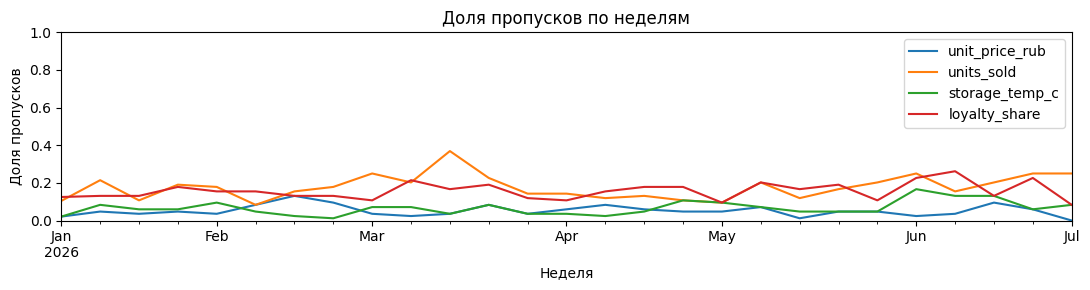

mean  size  missing_share
pos_version channel split                                    
v1          offline production  0.525268   120       0.316667
                    test        0.525388   120       0.333333
                    train       0.510965   480       0.289583
v2          offline production  0.431248   180       0.083333
                    test        0.434839   180       0.105556
                    train       0.434095   720       0.090278
            online  production  0.717000    60       0.333333
                    test        0.665117    60       0.000000
                    train       0.700565   240       0.041667

Доля пропусков по магазинам (delivery_min — только online):


,unit_price_rub,storage_temp_c,delivery_min
store_id,,,
S10,0.067,0.033,0.033
S11,0.050,0.056,0.111


Февраль, доля пропусков S03 vs остальные:


,storage_temp_c,unit_price_rub
is_S03,,
False,0.032,0.065
True,0.107,0.321


Корреляция индикаторов пропуска между полями:


,unit_price_rub,units_sold,storage_temp_c,loyalty_share,lab_score
unit_price_rub,1.00,0.05,0.00,0.01,0.02
units_sold,0.05,1.00,-0.00,0.01,-0.01
storage_temp_c,0.00,-0.00,1.00,0.08,-0.03
loyalty_share,0.01,0.01,0.08,1.00,-0.01
lab_score,0.02,-0.01,-0.03,-0.01,1.00


In [11]:
df['date'] = pd.to_datetime(df['date'])           # ensure datetime, not string
df['week'] = df['date'].dt.to_period('W')          # Monday-start weeks

fields = ['unit_price_rub', 'units_sold', 'storage_temp_c', 'loyalty_share']
by_week = df.groupby('week')[fields].agg(lambda x: x.isna().mean())

ax = by_week.plot(figsize=(11, 3), ylim=(0, 1),
                  ylabel='Доля пропусков',
                  title='Доля пропусков по неделям')
ax.set_xlabel('Неделя')
plt.tight_layout(); plt.show()

# --- loyalty_share: сравнение версии кассы и канала ---
loy = (df.groupby(['pos_version', 'channel', 'split'])['loyalty_share']
         .agg(['mean', 'size', lambda x: x.isna().mean()])
         .rename(columns={'<lambda_0>': 'missing_share'}))
display(loy)

# --- Три операционных поля: сравнение магазинов (delivery_min — только online) ---
ops = ['unit_price_rub', 'storage_temp_c', 'delivery_min']
ops_online = df[df.channel.eq('online')]
print('Доля пропусков по магазинам (delivery_min — только online):')
display(ops_online.groupby('store_id')[ops].agg(lambda x: x.isna().mean()).round(3))

# --- S03 vs остальные в феврале ---
feb = df[pd.to_datetime(df.date).dt.month == 2].copy()
feb['is_S03'] = feb.store_id.eq('S03')
print('Февраль, доля пропусков S03 vs остальные:')
display(feb.groupby('is_S03')[['storage_temp_c', 'unit_price_rub']].agg(lambda x: x.isna().mean()).round(3))

# --- Совместные корреляции индикаторов пропуска ---
miss = df[fields + ['lab_score']].isna()
print('Корреляция индикаторов пропуска между полями:')
display(miss.corr().round(2))

## 3 Сравнение стратегий
Оценки и пороги обучаются только на train. Контрольные скрытые ячейки benchmark_imputation не участвуют в расчёте среднего/медианы.

In [4]:
train = df.loc[df.split.eq('train')].copy()
test  = df.loc[df.split.eq('test')].copy()
production = df.loc[df.split.eq('production')].copy()

# --- 1) Искусственная проверка на наблюдаемых train-ячейках ---
bench = benchmark_imputation(train)
display(bench)
print('Низкий MAE здесь не доказывает качество восстановления MNAR: '
      'скрытые ячейки были MCAR-подобными и лежали на наблюдаемом распределении.')

# --- 2) Среднее vs медиана на train ---
fit_mean   = train.loyalty_share.mean()
fit_median = train.loyalty_share.median()
print(f'Параметры train: среднее={fit_mean:.4f}, медиана={fit_median:.4f}')

observed = train.loyalty_share.copy()
comparison = pd.DataFrame({
    'observed':       observed,
    'mean_imputed':   observed.fillna(fit_mean),
    'median_imputed': observed.fillna(fit_median),
}).agg(['mean', 'std', 'count'])
display(comparison)
n_missing_train = int(train.loyalty_share.isna().sum())
print(f'Ячеек с пропуском в train: {n_missing_train} — все они будут изменены при заполнении.')

# --- 3) Выбор стратегии: медиана + missing indicator ---
# Медиана устойчивее: loyalty_share скошен (много нулей), среднее тянется вверх.
work = df.copy()
work['loyalty_was_missing'] = work.loyalty_share.isna().astype(int)
before_mean, before_std = work.loyalty_share.mean(), work.loyalty_share.std(ddof=0)
work['loyalty_share'] = work.loyalty_share.fillna(fit_median)   # параметр только из train
after_mean,  after_std  = work.loyalty_share.mean(),  work.loyalty_share.std(ddof=0)
print(f'loyalty_share до:  mean={before_mean:.4f}, std={before_std:.4f}')
print(f'loyalty_share после: mean={after_mean:.4f}, std={after_std:.4f}')
print(f'Изменено ячеек: {int(work.loyalty_was_missing.sum())}')

# --- 4) delivery_min: не заполняем offline общей медианой ---
delivery_median_train = train.loc[train.channel.eq('online'), 'delivery_min'].median()
work.loc[work.channel.eq('online'), 'delivery_min'] = (
    work.loc[work.channel.eq('online'), 'delivery_min'].fillna(delivery_median_train)
)
# offline оставляем NaN — это структурная неприменимость
print(f'Заполнено delivery_min online медианой train={delivery_median_train:.2f}; '
      'offline по-прежнему NaN.')

# --- 5) Отрицательные значения = ошибки диапазона, не missing-коды ---
work['price_range_error'] = work.unit_price_rub.lt(0).astype(int)
work['units_range_error'] = work.units_sold.lt(0).astype(int)
print('Отрицательных цен:', int(work.price_range_error.sum()))
print('Отрицательных units_sold:', int(work.units_range_error.sum()))
print('Оставлены как есть и помечены флагами — не заменены на NaN.')


,method,fit_value,mae,validation_cells
0,mean,0.505127,0.172324,245
1,median,0.536000,0.169237,245


Низкий MAE здесь не доказывает качество восстановления MNAR: скрытые ячейки были MCAR-подобными и лежали на наблюдаемом распределении.
Параметры train: среднее=0.5055, медиана=0.5395


,observed,mean_imputed,median_imputed
mean,0.505466,0.505466,0.510524
std,0.223290,0.206018,0.206374
count,1226.000000,1440.000000,1440.000000


Ячеек с пропуском в train: 214 — все они будут изменены при заполнении.
loyalty_share до:  mean=0.5042, std=0.2230
loyalty_share после: mean=0.5098, std=0.2047
Изменено ячеек: 346
Заполнено delivery_min online медианой train=49.75; offline по-прежнему NaN.
Отрицательных цен: 1
Отрицательных units_sold: 1
Оставлены как есть и помечены флагами — не заменены на NaN.


## 4 Выбросы
Глобальное правило и контекст могут дать разные решения. Подготовьте разбор пяти record_id.

In [5]:
bounds = iqr_bounds(train.units_sold)
work['iqr_flag'] = flag_outside(work.units_sold, bounds)
mu, sd = train.units_sold.mean(), train.units_sold.std(ddof=0)
work['z_flag'] = ((work.units_sold - mu) / sd).abs().gt(3)

n_iqr, n_z = int(work.iqr_flag.sum()), int(work.z_flag.sum())
print(f'IQR-флагов: {n_iqr} | z-флагов: {n_z}')
print(f'Пересечение: {int((work.iqr_flag & work.z_flag).sum())} | '
      f'только IQR: {int((work.iqr_flag & ~work.z_flag).sum())} | '
      f'только z: {int((~work.iqr_flag & work.z_flag).sum())}')
display(work.groupby('customer_segment')[['iqr_flag', 'z_flag']].sum())

# --- Сегментный IQR: пороги только из train своей группы ---
seg_bounds = {seg: iqr_bounds(g.units_sold) for seg, g in train.groupby('customer_segment')}
for seg, b in seg_bounds.items():
    print(seg, '→ границы IQR (только train):', b)

work['seg_iqr_flag'] = False
for seg, b in seg_bounds.items():
    m = work.customer_segment.eq(seg)
    work.loc[m, 'seg_iqr_flag'] = flag_outside(work.loc[m, 'units_sold'], b)

b2b = work.customer_segment.eq('B2B')
print('B2B: глобальный IQR пометил', int((work.iqr_flag & b2b).sum()),
      '| сегментный IQR пометил', int((work.seg_iqr_flag & b2b).sum()))

# --- Кандидаты для разбора пяти record_id ---
print('\nКандидаты на разбор:')
cols = ['record_id', 'store_id', 'customer_segment', 'units_sold',
        'unit_price_rub', 'stockout_flag', 'iqr_flag', 'z_flag']
cand = []

# 1) явная ошибка диапазона
err = work[(work.units_range_error == 1) | (work.price_range_error == 1)].head(2)
cand.append(err)
# 2) корректное редкое значение: флаг IQR, но не stockout и не 0
rare = work[work.iqr_flag & work.units_sold.gt(0) & ~work.stockout_flag.fillna(0).astype(bool)].head(2)
cand.append(rare)
# 3) настоящий ноль
cand.append(work[work.units_sold.eq(0)].head(2))
# 4) спорные: z_flag без IQR
cand.append(work[work.z_flag & ~work.iqr_flag].head(2))
# 5) спорные: IQR без z
cand.append(work[work.iqr_flag & ~work.z_flag].head(2))

five = pd.concat(cand).drop_duplicates('record_id').head(5)
display(five[cols])

# --- Разбор пяти записей: структура для отчёта ---
five_review = five[cols].copy()

# На всякий случай приводим флаги к bool (могут быть object/NaN из flag_outside)
iqr_f = five_review['iqr_flag'].fillna(False).astype(bool)
z_f   = five_review['z_flag'].fillna(False).astype(bool)

# Контекст флага — строим через pd.Series, а не numpy-массив
context = pd.Series('нет', index=five_review.index)
context[iqr_f & z_f]  = 'IQR+z'
context[iqr_f & ~z_f] = 'IQR'
context[~iqr_f & z_f] = 'z'

five_review['поле']     = 'units_sold'
five_review['контекст'] = 'флаг ' + context

five_review['действие'] = five_review.apply(
    lambda r: 'исключить из конкретного расчёта'
    if (pd.notna(r.units_sold) and r.units_sold < 0) or (pd.notna(r.unit_price_rub) and r.unit_price_rub < 0)
    else ('проверить источник'
          if (pd.notna(r.stockout_flag) and r.stockout_flag == 1) or (pd.notna(r.units_sold) and r.units_sold == 0)
          else 'оставить / сегментировать'),
    axis=1,
)

five_review['основание'] = five_review.apply(
    lambda r: 'значение вне допустимого диапазона'
    if (pd.notna(r.units_sold) and r.units_sold < 0) or (pd.notna(r.unit_price_rub) and r.unit_price_rub < 0)
    else ('нулевые продажи — реальное наблюдение спроса'
          if (pd.notna(r.units_sold) and r.units_sold == 0)
          else ('возможный stockout, а не ошибка'
                if (pd.notna(r.stockout_flag) and r.stockout_flag == 1)
                else 'редкое, но правдоподобное значение; правильное значение неизвестно')),
    axis=1,
)

display(five_review[['record_id', 'поле', 'контекст', 'действие', 'основание']])


IQR-флагов: 190 | z-флагов: 36
Пересечение: 36 | только IQR: 154 | только z: 0


,iqr_flag,z_flag
customer_segment,,
B2B,145,35
B2C,45,1


B2B → границы IQR (только train): (-2.375, 772.625)
B2C → границы IQR (только train): (-5.5, 62.5)
B2B: глобальный IQR пометил 145 | сегментный IQR пометил 5

Кандидаты на разбор:


,record_id,store_id,customer_segment,units_sold,unit_price_rub,stockout_flag,iqr_flag,z_flag
31883,R031884,S10,B2C,-43.0,-123.27,0,True,False
30301,R030302,S01,B2C,85.0,95.94,0,True,False
30320,R030321,S01,B2C,118.0,121.15,0,True,False
30292,R030293,S01,B2C,0.0,120.34,1,False,False
30308,R030309,S01,B2C,0.0,118.57,1,False,False


,record_id,поле,контекст,действие,основание
31883,R031884,units_sold,флаг IQR,исключить из конкретного расчёта,значение вне допустимого диапазона
30301,R030302,units_sold,флаг IQR,оставить / сегментировать,"редкое, но правдоподобное значение; правильное..."
30320,R030321,units_sold,флаг IQR,оставить / сегментировать,"редкое, но правдоподобное значение; правильное..."
30292,R030293,units_sold,флаг нет,проверить источник,нулевые продажи — реальное наблюдение спроса
30308,R030309,units_sold,флаг нет,проверить источник,нулевые продажи — реальное наблюдение спроса


## 5 Последствия и мониторинг
Замените work на реально обработанную копию; не выдавайте одинаковые таблицы за проверку изменений.

In [6]:
display(summary_before_after(df, work))

# --- Мониторинг storage_temp_c в S03/S07 ---
monitor = (df.loc[df.store_id.isin(['S03', 'S07'])]
             .groupby('split')['storage_temp_c']
             .agg(lambda x: x.isna().mean()))
display(monitor)
delta_temp = 100 * (monitor['production'] - monitor['train'])
print(f'storage_temp_c S03/S07: train → production = {delta_temp:+.1f} п.п.')

# --- Мониторинг loyalty_share только online ---
online_df = df[df.channel.eq('online')]
mon_loy = online_df.groupby('split')['loyalty_share'].agg(lambda x: x.isna().mean())
display(mon_loy)
delta_loy = 100 * (mon_loy['production'] - mon_loy['train'])
print(f'loyalty_share (online): train → production = {delta_loy:+.1f} п.п.')
print('Порог тревоги: >10 п.п. — это правило мониторинга, а не статистический тест.')

# --- Корреляция «до/после» на фактически изменённом поле ---
valid_before = df[['units_sold', 'unit_price_rub']].dropna()
valid_after  = work[['units_sold', 'unit_price_rub']].dropna()
r_before = valid_before.units_sold.corr(valid_before.unit_price_rub)
r_after  = valid_after.units_sold.corr(valid_after.unit_price_rub)
print(f'corr(units_sold, unit_price_rub): '
      f'до {r_before:.3f} (n={len(valid_before)}), '
      f'после {r_after:.3f} (n={len(valid_after)})')


,before,after
rows,2160.000000,2160.000000
units_mean,63.587971,63.587971
units_median,29.000000,29.000000
units_std,136.321584,136.321584
b2b_share,0.083333,0.083333
missing_qty_share,0.176389,0.176389


split
production    0.500000
test          0.050000
train         0.054167
Name: storage_temp_c, dtype: float64

storage_temp_c S03/S07: train → production = +44.6 п.п.


split
production    0.333333
test          0.000000
train         0.041667
Name: loyalty_share, dtype: float64

loyalty_share (online): train → production = +29.2 п.п.
Порог тревоги: >10 п.п. — это правило мониторинга, а не статистический тест.
corr(units_sold, unit_price_rub): до 0.145 (n=1692), после 0.145 (n=1692)


## 6 Вывод и журнал
Заполните журнал минимум шестью решениями. Вывод 150–200 слов, ограничения и три исправления плохого плана очистки.

In [7]:
decisions = pd.DataFrame([
    {'record_id_or_field': 'delivery_min',
     'problem': 'пропуски у offline (структурная неприменимость)',
     'action': 'оставить NaN, заполнить медианой train только online',
     'reason': 'у offline доставки нет по определению',
     'changed_count': int(work.loc[work.channel.eq('online'), 'delivery_min'].notna().sum()
                          - df.loc[df.channel.eq('online'), 'delivery_min'].notna().sum())},

    {'record_id_or_field': 'loyalty_share',
     'problem': f'пропуски в train ({n_missing_train} ячеек)',
     'action': 'заполнить медианой train + missing indicator',
     'reason': 'медиана устойчива к скошенности; индикатор сохраняет факт пропуска',
     'changed_count': int(work.loyalty_was_missing.sum())},

    {'record_id_or_field': 'units_sold',
     'problem': 'отрицательные значения (ошибки диапазона)',
     'action': 'пометить флагом, не заменять на NaN',
     'reason': 'это не missing-код, а ошибка диапазона; источник неизвестен',
     'changed_count': int(work.units_range_error.sum())},

    {'record_id_or_field': 'unit_price_rub',
     'problem': 'отрицательные значения',
     'action': 'пометить флагом price_range_error',
     'reason': 'смешивать с пропуском нельзя; интерполировать такие строки некорректно',
     'changed_count': int(work.price_range_error.sum())},

    {'record_id_or_field': 'units_sold',
     'problem': 'выбросы за 1.5*IQR (глобальный и сегментный)',
     'action': 'флаги iqr_flag и seg_iqr_flag; строки не удалять',
     'reason': 'часть флагов — реальные оптовые отгрузки B2B',
     'changed_count': int(work.iqr_flag.sum())},

    {'record_id_or_field': 'lab_score',
     'problem': f'низкая заполненность ({df.lab_score.notna().mean()*100:.1f}%)',
     'action': 'не удалять строки; в отчёте отметить как ненадёжный признак',
     'reason': 'удаление по заполненности искажает состав выборки',
     'changed_count': 0},
])
display(decisions)

# --- Сохранение результатов ---
output = Path('my_output'); output.mkdir(exist_ok=True)
audit.to_csv(output/'audit.csv', sep=';', encoding='utf-8-sig')
codes_table.to_csv(output/'missing_codes_count.csv', sep=';', encoding='utf-8-sig')
bench.to_csv(output/'benchmark_imputation.csv', sep=';', encoding='utf-8-sig')
five_review.to_csv(output/'five_record_ids.csv', sep=';', encoding='utf-8-sig')
work.to_csv(output/'work_processed.csv', sep=';', encoding='utf-8-sig')
decisions.to_csv(output/'decisions.csv', sep=';', encoding='utf-8-sig')

# графики
ax.figure.savefig(output/'missing_by_day.png', dpi=120, bbox_inches='tight')
print('Готово. Файлы сохранены в my_output/')

conclusion = (
    'Обнаружены: документированные коды пропусков в loyalty_share и операционных полях; '
    'структурная неприменимость delivery_min у offline; настоящие нули units_sold и loyalty_share; '
    'ошибки диапазона (отрицательные цены/количество); низкая заполненность lab_score; '
    'выбросы, часть которых — корректные B2B-отгрузки. '
    'Изменено: loyalty_share заполнен медианой train (+indicator), delivery_min — только online, '
    'остальные пропуски сохранены как NaN и помечены флагами. Сохранены нули продаж, '
    'B2B-выбросы и строки с lab_score. Наиболее рискованное допущение — что пропуски '
    'loyalty_share MAR и медиана train адекватна для production. '
    'Без источника нельзя установить: MNAR-механизм lab_score, причину недельного провала цены, '
    'истинное значение отрицательных цен и количества. '
    'Исправления плохого плана: (1) не заполнять нулями — 0 это наблюдение; '
    '(2) не удалять за 1.5-IQR — часть флагов полезна; '
    '(3) не считать параметры на всей таблице — только на train.'
)
print(conclusion)


,record_id_or_field,problem,action,reason,changed_count
0,delivery_min,пропуски у offline (структурная неприменимость),"оставить NaN, заполнить медианой train только ...",у offline доставки нет по определению,26
1,loyalty_share,пропуски в train (214 ячеек),заполнить медианой train + missing indicator,медиана устойчива к скошенности; индикатор сох...,346
2,units_sold,отрицательные значения (ошибки диапазона),"пометить флагом, не заменять на NaN","это не missing-код, а ошибка диапазона; источн...",1
3,unit_price_rub,отрицательные значения,пометить флагом price_range_error,смешивать с пропуском нельзя; интерполировать ...,1
4,units_sold,выбросы за 1.5*IQR (глобальный и сегментный),флаги iqr_flag и seg_iqr_flag; строки не удалять,часть флагов — реальные оптовые отгрузки B2B,190
5,lab_score,низкая заполненность (5.5%),не удалять строки; в отчёте отметить как ненад...,удаление по заполненности искажает состав выборки,0


Готово. Файлы сохранены в my_output/
Обнаружены: документированные коды пропусков в loyalty_share и операционных полях; структурная неприменимость delivery_min у offline; настоящие нули units_sold и loyalty_share; ошибки диапазона (отрицательные цены/количество); низкая заполненность lab_score; выбросы, часть которых — корректные B2B-отгрузки. Изменено: loyalty_share заполнен медианой train (+indicator), delivery_min — только online, остальные пропуски сохранены как NaN и помечены флагами. Сохранены нули продаж, B2B-выбросы и строки с lab_score. Наиболее рискованное допущение — что пропуски loyalty_share MAR и медиана train адекватна для production. Без источника нельзя установить: MNAR-механизм lab_score, причину недельного провала цены, истинное значение отрицательных цен и количества. Исправления плохого плана: (1) не заполнять нулями — 0 это наблюдение; (2) не удалять за 1.5-IQR — часть флагов полезна; (3) не считать параметры на всей таблице — только на train.


In [13]:
print(f"{(df.isna().sum().sum() / df.size) * 100:.2f}% of all cells are missing")

8.50% of all cells are missing


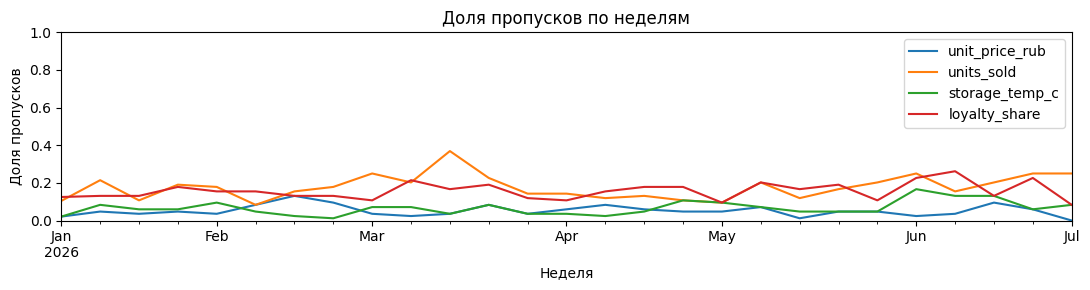

In [14]:
df['date'] = pd.to_datetime(df['date'])           # ensure datetime, not string
df['week'] = df['date'].dt.to_period('W')          # Monday-start weeks

fields = ['unit_price_rub', 'units_sold', 'storage_temp_c', 'loyalty_share']
by_week = df.groupby('week')[fields].agg(lambda x: x.isna().mean())

ax = by_week.plot(figsize=(11, 3), ylim=(0, 1),
                  ylabel='Доля пропусков',
                  title='Доля пропусков по неделям')
ax.set_xlabel('Неделя')
plt.tight_layout(); plt.show()